# End-to-End Human-in-the-Loop Face Recognition Pipeline

This notebook covers data auditing, preprocessing, feature visualizations, model training, evaluation, a confusion matrix, and single-image prediction.

Use facial images only when the people represented know about and consent to this use.


In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

os.environ.pop("MPLBACKEND", None)
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt


In [2]:
%matplotlib inline
import os
import sys
import warnings
warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

from pathlib import Path

import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics.pairwise import cosine_similarity

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.detector import FaceDetectorEmbedder
from src.train import train_classifier
from src.evaluate import evaluate_model

# Re-assert inline backend (insightface resets it to Agg on import)
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import importlib; importlib.reload(plt)

sns.set_theme(style="whitegrid")

KNOWN_DIR = "data/known_faces"
TEST_DIR = "data/test_set"
MODEL_PATH = "models/classifier.pkl"
PLOTS_DIR = "data/logs/plots"
SIM_THRESHOLD = 0.55
VALID_EXTENSIONS = (".jpg", ".jpeg", ".png", ".webp")

os.makedirs(PLOTS_DIR, exist_ok=True)
print("Working directory:", os.getcwd())


Working directory: /home/abdalazizi/face-detection


## 1. Data acquisition and preprocessing feature audit

Audit each labeled image for its identity, dimensions, pixel area, Laplacian sharpness, and mean grayscale brightness. These are dataset-quality features; the detector separately extracts face embeddings for recognition.


In [3]:
detector = FaceDetectorEmbedder(
    det_size=(640, 640),
    min_face_size=50,
    blur_threshold=15.0,
)

if not os.path.isdir(KNOWN_DIR):
    raise FileNotFoundError(f"Training directory not found: {KNOWN_DIR}")

records = []

for person in sorted(os.listdir(KNOWN_DIR)):
    person_dir = os.path.join(KNOWN_DIR, person)
    if not os.path.isdir(person_dir):
        continue

    for filename in sorted(os.listdir(person_dir)):
        if not filename.lower().endswith(VALID_EXTENSIONS):
            continue

        image_path = os.path.join(person_dir, filename)
        image = cv2.imread(image_path)
        if image is None:
            print(f"Skipping unreadable image: {image_path}")
            continue

        height, width = image.shape[:2]
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        records.append({
            "Person": person,
            "Filename": filename,
            "Width": width,
            "Height": height,
            "Pixel_Area": width * height,
            "Sharpness_Score": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
            "Mean_Brightness": float(np.mean(gray)),
        })

df_features = pd.DataFrame(records)
print(f"Total labeled images audited: {len(df_features)}")
display(df_features.head())


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /home/abdalazizi/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /home/abdalazizi/.insightface/models/buffalo_l/2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /home/abdalazizi/.insightface/models/buffalo_l/det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /home/abdalazizi/.insightface/models/buffalo_l/genderage.onnx genderage ['None', 3, 96, 96] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /home/abdalazizi/.insightface/models/buffalo_l/w600k_r50.onnx recognition ['None', 3, 112,

,Person,Filename,Width,Height,Pixel_Area,Sharpness_Score,Mean_Brightness
0,Chinese,2d8c1521.jpg,896,1122,1005312,35.366528,113.567295
1,Ornella,0c9c2a74.jpg,451,630,284130,50.559113,135.049403
2,Ornella,29d74ac3.jpg,98,127,12446,3577.938500,85.152820
3,Ornella,6ddd640e.jpg,98,127,12446,3577.938500,85.152820
4,Twariq,1191c5a4.jpg,193,266,51338,457.805129,150.468834


## 2. Dataset feature visualizations

The three plots examine class sample counts, image sharpness, and brightness versus sharpness. They are descriptive diagnostics, not proof of model accuracy or fairness.


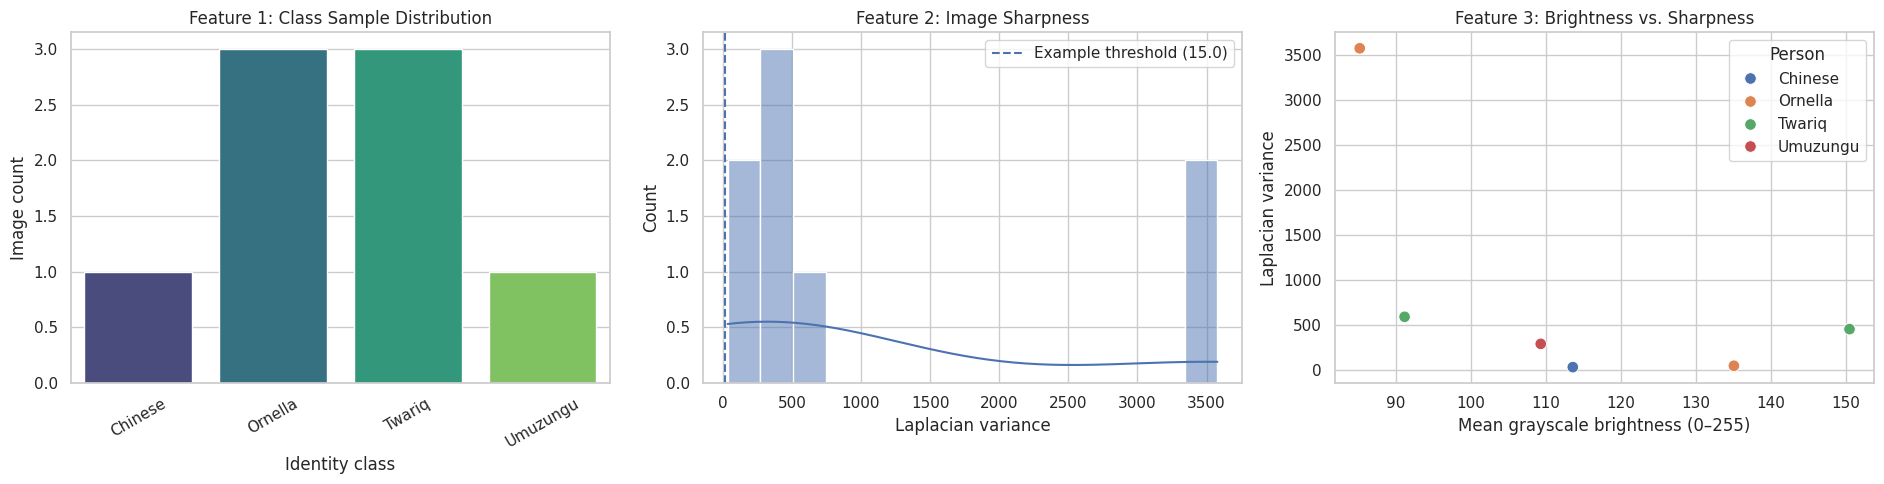

In [4]:
if df_features.empty:
    raise ValueError(f"No readable training images found under {KNOWN_DIR}.")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# Feature 1: class sample distribution
counts = df_features["Person"].value_counts().sort_index()
sns.barplot(
    x=counts.index,
    y=counts.values,
    hue=counts.index,
    dodge=False,
    palette="viridis",
    ax=axes[0],
    legend=False,
)
axes[0].set_title("Feature 1: Class Sample Distribution")
axes[0].set_xlabel("Identity class")
axes[0].set_ylabel("Image count")
axes[0].tick_params(axis="x", rotation=30)

# Feature 2: sharpness distribution
sns.histplot(
    data=df_features,
    x="Sharpness_Score",
    bins=15,
    kde=True,
    ax=axes[1],
)
axes[1].axvline(15.0, linestyle="--", label="Example threshold (15.0)")
axes[1].set_title("Feature 2: Image Sharpness")
axes[1].set_xlabel("Laplacian variance")
axes[1].legend()

# Feature 3: brightness versus sharpness
sns.scatterplot(
    data=df_features,
    x="Mean_Brightness",
    y="Sharpness_Score",
    hue="Person",
    s=70,
    ax=axes[2],
)
axes[2].set_title("Feature 3: Brightness vs. Sharpness")
axes[2].set_xlabel("Mean grayscale brightness (0–255)")
axes[2].set_ylabel("Laplacian variance")

plt.tight_layout()
plt.savefig(
    os.path.join(PLOTS_DIR, "notebook_feature_distributions.png"),
    dpi=150,
    bbox_inches="tight",
)
plt.show()


### Interpretation of dataset features

1. **Class sample distribution:** reveals differences in the number of images per identity. Imbalanced sample counts can affect model performance.
2. **Image sharpness:** Laplacian variance is a rough focus indicator. The dashed line is illustrative; actual filtering depends on the detector's implementation and configured threshold.
3. **Brightness versus sharpness:** helps identify images with unusual lighting or focus. It does not establish that lighting is consistent or that the model relies only on facial features.


## 3. Offline model training and embedding visualization

Train the classifier using the project's training function, then use PCA to project the stored embeddings into two dimensions.


Starting training...
Using Support Vector Classifier
Training summary: {'status': 'success', 'num_samples': 8, 'classes': ['Chinese', 'Ornella', 'Twariq', 'Umuzungu'], 'model_type': 'svm'}
Embedding matrix shape: (8, 512)
Number of labels: 8
Model type: svm


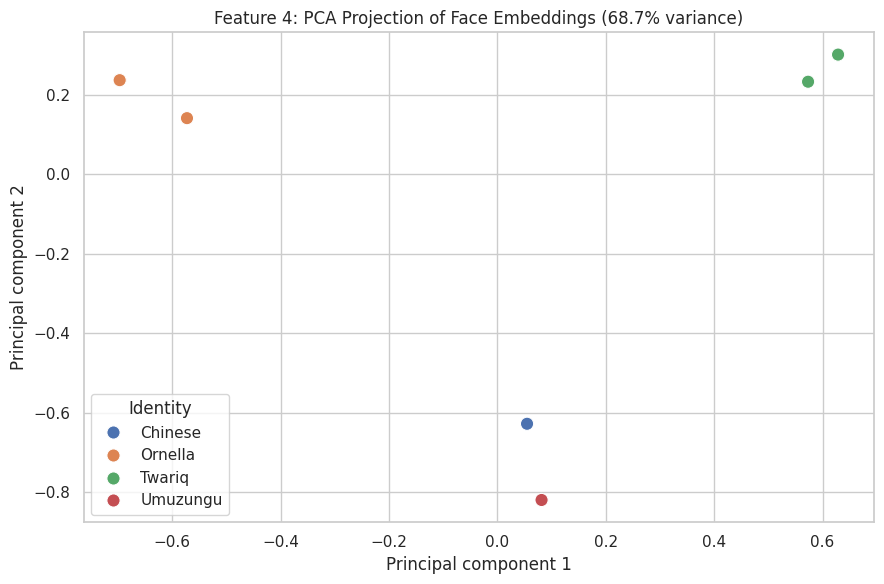

In [5]:
train_result = train_classifier(
    known_dir=KNOWN_DIR,
    model_path=MODEL_PATH,
    detector=detector,
)
print("Training summary:", train_result)

if train_result.get("status") != "success":
    raise RuntimeError(train_result.get("message", "Model training failed."))

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(f"Model artifact not found: {MODEL_PATH}")

artifact = joblib.load(MODEL_PATH)
X_emb = np.asarray(artifact["embeddings"])
y_labels = np.asarray(artifact["labels"])

print("Embedding matrix shape:", X_emb.shape)
print("Number of labels:", len(y_labels))
print("Model type:", artifact.get("model_type"))

if X_emb.ndim != 2 or X_emb.shape[0] != len(y_labels):
    raise ValueError("Stored embeddings and labels do not have matching rows.")
if X_emb.shape[0] < 2 or X_emb.shape[1] < 2:
    raise ValueError("PCA requires at least two samples and two dimensions.")

pca = PCA(n_components=2)
coordinates = pca.fit_transform(X_emb)
variance_explained = pca.explained_variance_ratio_.sum() * 100

pca_df = pd.DataFrame({
    "PC1": coordinates[:, 0],
    "PC2": coordinates[:, 1],
    "Identity": y_labels,
})

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Identity", s=90)
plt.title(
    "Feature 4: PCA Projection of Face Embeddings "
    f"({variance_explained:.1f}% variance)"
)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.tight_layout()
plt.savefig(
    os.path.join(PLOTS_DIR, "notebook_pca_embeddings.png"),
    dpi=150,
    bbox_inches="tight",
)
plt.show()


### Interpretation of Feature 4

PCA reduces the embedding vectors to two dimensions while retaining as much variance as possible. Points close together have similar projected representations, but a two-dimensional projection can hide differences in the original embedding space. Visual separation alone does not prove reliable real-world recognition.


## 4. Model evaluation and confusion matrix

Run the project's evaluation function first. The following cell separately builds a confusion matrix using cosine-similarity thresholding and the saved classifier.


In [6]:
eval_metrics = evaluate_model(
    test_dir=TEST_DIR,
    model_path=MODEL_PATH,
    sim_threshold=SIM_THRESHOLD,
    detector=detector,
)

for key, value in eval_metrics.items():
    if key != "classification_report":
        print(f"{key}: {value}")

print("\nDetailed classification report:\n")
print(eval_metrics.get("classification_report", ""))


status: success
total_test_samples: 7
sim_threshold: 0.55
accuracy: 1.0
precision: 1.0
recall: 1.0
f1_score: 1.0
unknown_rejection_rate: N/A (No Unknown folder)
false_acceptance_rate: N/A
plots: {'confusion_matrix': 'data/logs/plots/confusion_matrix.png', 'similarity_distribution': 'data/logs/plots/similarity_distribution.png', 'class_metrics': 'data/logs/plots/class_metrics.png'}

Detailed classification report:

              precision    recall  f1-score   support

     Ornella       1.00      1.00      1.00         4
      Twariq       1.00      1.00      1.00         3

    accuracy                           1.00         7
   macro avg       1.00      1.00      1.00         7
weighted avg       1.00      1.00      1.00         7



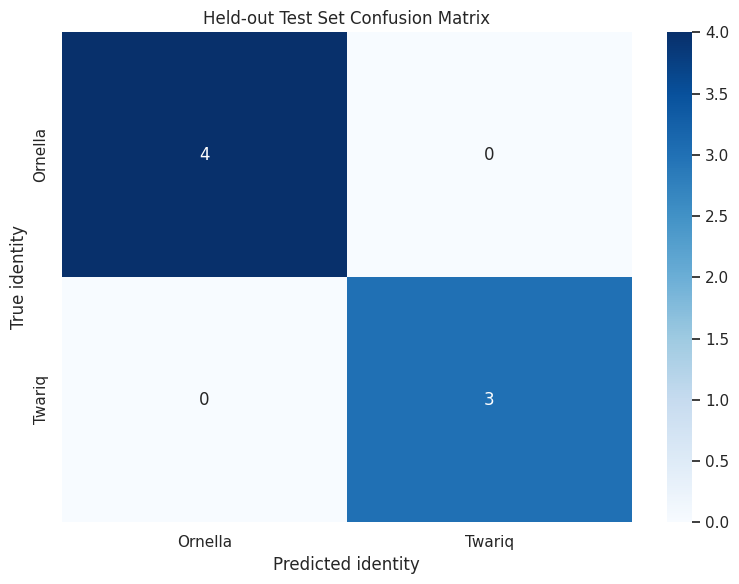

              precision    recall  f1-score   support

     Ornella       1.00      1.00      1.00         4
      Twariq       1.00      1.00      1.00         3

    accuracy                           1.00         7
   macro avg       1.00      1.00      1.00         7
weighted avg       1.00      1.00      1.00         7



In [7]:
def predict_embedding(embedding, model_artifact, threshold=SIM_THRESHOLD):
    embedding = np.asarray(embedding).reshape(1, -1)
    similarities = cosine_similarity(
        embedding,
        model_artifact["embeddings"],
    )

    best_index = int(np.argmax(similarities[0]))
    best_similarity = float(similarities[0, best_index])

    if best_similarity < threshold:
        return "Unknown", best_similarity

    if model_artifact.get("model_type") == "svm":
        prediction = model_artifact["classifier"].predict(embedding)
        return str(prediction[0]), best_similarity

    return str(model_artifact["labels"][best_index]), best_similarity


if not os.path.isdir(TEST_DIR):
    raise FileNotFoundError(f"Test directory not found: {TEST_DIR}")

y_true = []
y_pred = []

def bbox_area(face):
    x1, y1, x2, y2 = face["bbox"]
    return max(0, x2 - x1) * max(0, y2 - y1)

for folder_name in sorted(os.listdir(TEST_DIR)):
    folder_path = os.path.join(TEST_DIR, folder_name)
    if not os.path.isdir(folder_path):
        continue

    for image_name in sorted(os.listdir(folder_path)):
        if not image_name.lower().endswith(VALID_EXTENSIONS):
            continue

        image_path = os.path.join(folder_path, image_name)
        image = cv2.imread(image_path)
        if image is None:
            continue

        detected_faces = detector.extract_faces(image)
        if not detected_faces:
            continue

        largest_face = max(detected_faces, key=bbox_area)
        predicted_label, _ = predict_embedding(
            largest_face["embedding"],
            artifact,
            threshold=SIM_THRESHOLD,
        )

        y_true.append(folder_name)
        y_pred.append(predicted_label)

if y_true:
    labels_sorted = sorted(set(y_true) | set(y_pred))
    cm = confusion_matrix(y_true, y_pred, labels=labels_sorted)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels_sorted,
        yticklabels=labels_sorted,
    )
    plt.title("Held-out Test Set Confusion Matrix")
    plt.xlabel("Predicted identity")
    plt.ylabel("True identity")
    plt.tight_layout()
    plt.savefig(
        os.path.join(PLOTS_DIR, "notebook_confusion_matrix.png"),
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

    print(classification_report(
        y_true,
        y_pred,
        labels=labels_sorted,
        zero_division=0,
    ))
else:
    print(
        "No test predictions were produced. Check the test-set folders "
        "and whether the detector finds faces in the images."
    )


## 5. Single-image prediction demonstration

The function below accepts an image path and returns a predicted label, similarity score, and bounding box for each detected face.


In [8]:
def predict_single_image(
    image_path: str,
    model_path: str = MODEL_PATH,
    threshold: float = SIM_THRESHOLD,
):
    if not os.path.isfile(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")
    if not os.path.isfile(model_path):
        raise FileNotFoundError(f"Model artifact not found: {model_path}")

    loaded_artifact = joblib.load(model_path)
    frame = cv2.imread(image_path)
    if frame is None:
        raise ValueError(f"Could not read image: {image_path}")

    detected_faces = detector.extract_faces(frame)
    results = []

    for face in detected_faces:
        label, similarity = predict_embedding(
            face["embedding"],
            loaded_artifact,
            threshold=threshold,
        )
        results.append({
            "predicted_label": label,
            "similarity": round(similarity, 4),
            "bbox": face["bbox"],
        })

    return results


sample_test_image = None

for root, _, filenames in os.walk(TEST_DIR):
    for filename in sorted(filenames):
        if filename.lower().endswith(VALID_EXTENSIONS):
            sample_test_image = os.path.join(root, filename)
            break
    if sample_test_image:
        break

if sample_test_image:
    print("Testing image:", sample_test_image)
    print("Prediction output:", predict_single_image(sample_test_image))
else:
    print("No test image was found for the single-image demonstration.")


Testing image: data/test_set/Ornella/Ornella Profile pic.jpeg
Prediction output: [{'predicted_label': 'Ornella', 'similarity': 0.9883, 'bbox': [247, 328, 624, 854]}]
